# Tide at each image

Each Sentinel-2 image is taken at one moment of the tide. This notebook places the 97 images of MAREA's Villaviciosa record on the tide of 2023–2025, tells whether each was taken on the flood or the ebb, shows the level each 3-km section of the ría sees at the overpass, and measures how much of the tide range the images cover.

Real data: the sample in `data/` holds EOT20 at the ría's mouth at every overpass, read again for every whole minute of delay from −45 to 180, and every 10 minutes over 2023–2025. It runs in a few seconds. Heights are metres on the scale of EOT20 (about mean sea level); times are UTC.

In [1]:
# ── Setup: run from the repository root, whichever folder the notebook was opened in ──
import hashlib                                      # sha256 of the inputs
import os                                           # the working directory
import platform                                     # the Python version
import sys                                          # where the library is imported from
import warnings                                     # the outputs show results, not the packages' warnings
from pathlib import Path

warnings.filterwarnings('ignore')
ROOT = Path.cwd() if (Path.cwd() / 'pyintertidal').is_dir() else Path.cwd().parent
os.chdir(ROOT)                                      # every path below is relative to the repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib                                   # figures
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import netCDF4                                      # the sample's format (read through xarray)
import numpy as np
import pandas as pd
import xarray as xr

import pyintertidal as pit                          # the MAREA library of this repository
from pyintertidal import coverage                   # how well a record samples the tide


def sha256(path):
    # sha256 of a file, read in 1 MB blocks
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


# ── Provenance: the branch, the versions, and the inputs checked by their sha256 ──
sums = dict(line.split()[::-1] for line in open('data/SHA256SUMS.txt', encoding='utf-8') if line.strip())
INPUTS = {f'data/{name}': sums[name] for name in ('villaviciosa_sample.nc', 'villaviciosa_tide_levels.csv')}
print('branch CARTOGRASS26 · notebooks/02_tide_per_image.ipynb')
print(f'Python {platform.python_version()} · pyintertidal {pit.__version__} · numpy {np.__version__} · '
      f'pandas {pd.__version__} · xarray {xr.__version__} · netCDF4 {netCDF4.__version__} · '
      f'matplotlib {matplotlib.__version__}')
for path, want in INPUTS.items():
    assert sha256(path) == want, path
    print(f'  {path:38s} sha256 {want[:16]}  ok')

branch CARTOGRASS26 · notebooks/02_tide_per_image.ipynb
Python 3.13.3 · pyintertidal 0.1.0 · numpy 2.4.6 · pandas 2.3.3 · xarray 2025.1.1 · netCDF4 1.7.4 · matplotlib 3.10.9
  data/villaviciosa_sample.nc            sha256 f5af038980e133cb  ok
  data/villaviciosa_tide_levels.csv      sha256 97101eb31c7adba4  ok


In [2]:
# ── The colours, as inline hex, and a plain style ───────────────────────────────
INK, GREY, RULE = '#1F2A30', '#6B7377', '#B8C7CC'   # text and lines; secondary; context
FLOOD, EBB = '#0098A0', '#E4572E'                   # rising or falling tide at the overpass


def metres(v):
    # a signed height with a true minus sign, for the text of the figures
    return f'{v:+.2f} m'.replace('-', '\u2212')


plt.rcParams.update({
    'figure.dpi': 100, 'font.size': 9, 'axes.titlesize': 9.5, 'axes.labelsize': 9,
    'text.color': INK, 'axes.labelcolor': INK, 'axes.edgecolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False, 'axes.unicode_minus': True,
})

## 1 · The images on the tide

An image is on the **flood** when the tide at the mouth is rising at the overpass (the level 30 minutes later is higher than 30 minutes earlier) and on the **ebb** when it is falling.

In [3]:
s = xr.open_dataset('data/villaviciosa_sample.nc')
t = pd.DatetimeIndex(s['t'].values)                         # the overpass instants, UTC
h0 = s['tide_level'].values                                 # the level at the mouth at each overpass, m
lv = s['tide_level_delayed']                                # the level `delay` minutes before each overpass, m
rate = lv.sel(delay=-30).values - lv.sel(delay=30).values   # the change over the hour around the overpass, m
flood = rate > 0                                            # rising: flood; falling: ebb
ts = pd.DatetimeIndex(s['series_time'].values)              # the tide at the mouth every 10 minutes, 2023-2025
hs = s['tide_series'].values.astype(float)
csv = pd.read_csv('data/villaviciosa_tide_levels.csv', float_precision='round_trip')
assert np.array_equal(csv['tide_m'].to_numpy(), h0)          # the CSV holds the same levels
clock = t.strftime('%H:%M')
print(f'{len(t)} images from {t[0]:%d %b %Y} to {t[-1]:%d %b %Y}, taken between {clock.min()} and {clock.max()} UTC')
print(f'{flood.sum()} on the flood and {(~flood).sum()} on the ebb; the tide changed by up to '
      f'{np.abs(rate).max():.2f} m in the hour around an overpass')

97 images from 06 Jan 2023 to 28 Dec 2025, taken between 11:06 and 11:25 UTC
55 on the flood and 42 on the ebb; the tide changed by up to 0.96 m in the hour around an overpass


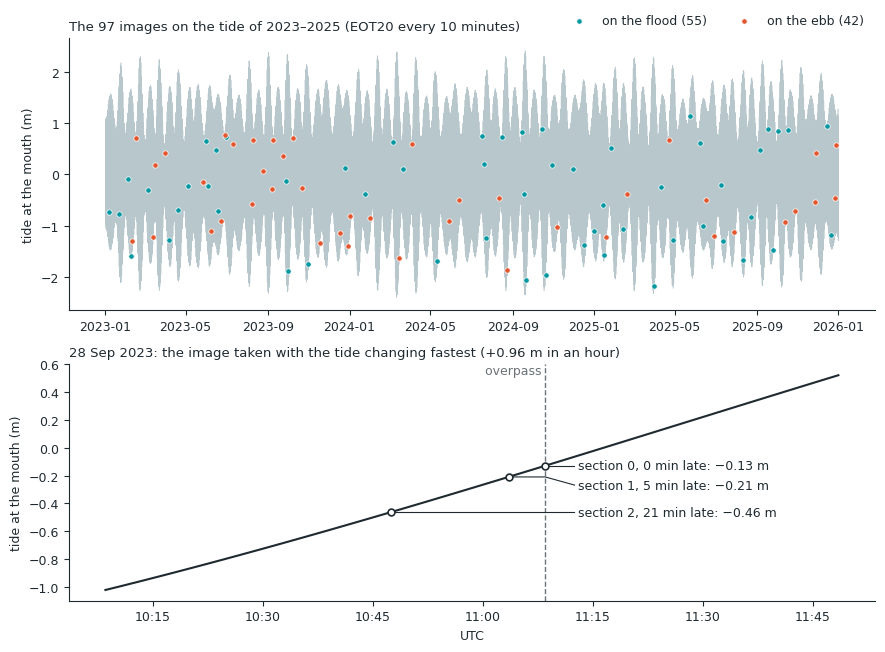

In [4]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6.6), gridspec_kw={'height_ratios': [1.15, 1]})

# (a) the three years: the tide every 10 minutes, and the images at their overpass
a1.plot(ts, hs, color=RULE, lw=0.4, zorder=1)
for mask, colour, label in ((flood, FLOOD, 'on the flood'), (~flood, EBB, 'on the ebb')):
    a1.scatter(t[mask], h0[mask], s=15, color=colour, edgecolor='white', linewidth=0.5, zorder=3,
               label=f'{label} ({mask.sum()})')
a1.set_ylabel('tide at the mouth (m)')
a1.set_title('The 97 images on the tide of 2023–2025 (EOT20 every 10 minutes)', loc='left')
a1.legend(loc='lower right', ncol=2, bbox_to_anchor=(1, 1.0))

# (b) one overpass, minute by minute: the level each section sees is the mouth's level, its delay earlier
i = int(np.argmax(np.abs(rate)))                            # the image taken with the tide changing fastest
minutes = np.arange(-40, 61)                                # 40 min after to 60 min before the overpass
curve = lv.sel(delay=minutes).values[i]                     # EOT20 at the mouth, minute by minute
a2.plot(t[i] - pd.to_timedelta(minutes, unit='min'), curve, color=INK, lw=1.5, zorder=2)
a2.axvline(t[i], color=GREY, lw=1, ls='--', zorder=1)
delays = np.round(s['band_delay_min'].values).astype(int)   # the sections' delays, to the minute
levels = [float(lv.sel(delay=int(d)).values[i]) for d in delays]   # what each section sees at the overpass
gap = 0.09 * (curve.max() - curve.min())                    # labels kept this far apart, in metres
label_y, below = {}, np.inf
for k in np.argsort(levels)[::-1]:                          # from the highest level down
    label_y[k] = min(levels[k], below - gap)
    below = label_y[k]
for k, (d, level) in enumerate(zip(delays, levels)):
    when = t[i] - pd.Timedelta(minutes=int(d))
    tip = t[i] + pd.Timedelta(minutes=4)
    a2.plot([when, t[i], tip], [level, level, label_y[k]], color=INK, lw=0.8, zorder=2)
    a2.scatter([when], [level], s=24, color='white', edgecolor=INK, linewidth=1.2, zorder=4)
    a2.text(tip, label_y[k], f' section {k}, {d} min late: {metres(level)}', va='center', color=INK)
a2.text(t[i], 1.0, 'overpass ', transform=a2.get_xaxis_transform(), ha='right', va='top', color=GREY)
a2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
a2.set_xlabel('UTC')
a2.set_ylabel('tide at the mouth (m)')
a2.set_title(f'{t[i]:%d %b %Y}: the image taken with the tide changing fastest ({rate[i]:+.2f} m in an hour)',
             loc='left')
fig.tight_layout()
plt.show()

## 2 · The level each section sees

MAREA divides the ría into 3-km sections along the water from the mouth and fits one delay per section (`band_delay_min`: 0, 5.05 and 20.74 minutes here). A pixel then reads the mouth's level its delay before the overpass; the pixels' own delays are the sections' delays smoothed along the distance from the mouth, to the minute. On the flood the water inside is still lower than at the mouth, and on the ebb it is still higher.

The table and the figure read every section at its fitted delay, rounded. The pixels themselves receive the smoothed delays: in the product, 1 to 4 min in section 0, 4 to 10 min in section 1 and 10 to 16 min in section 2 (medians 2, 6 and 14 min). The shifts applied to the pixels are therefore smaller than these, most of all in section 2 (`guide/METHOD.md`, section 5).

 section  centre (km)  delay (min)  read at (min)  mean shift, flood (cm)  mean shift, ebb (cm)  largest shift (cm)
       0         1.49         0.00              0                    0.00                  0.00                0.00
       1         4.27         5.05              5                   -4.19                  2.98                8.06
       2         7.57        20.74             21                  -17.00                 13.00               33.36


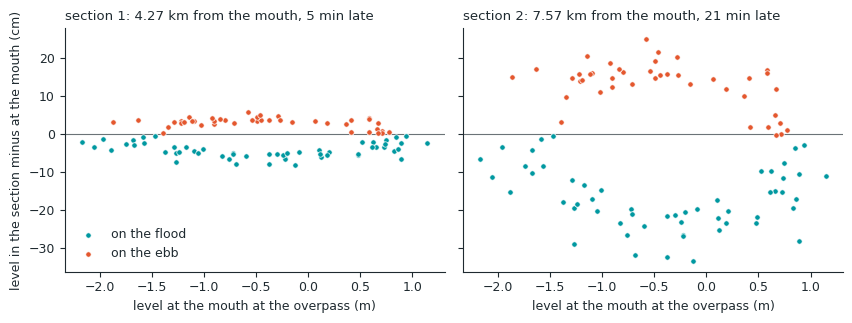

In [5]:
centres, fitted = s['band_centre_km'].values, s['band_delay_min'].values   # the product's sections
rows, shift = [], {}
for k, (centre, d_fit, d) in enumerate(zip(centres, fitted, delays)):
    shift[k] = 100 * (lv.sel(delay=int(d)).values - h0)     # cm: the section's level minus the mouth's
    rows.append((k, centre, d_fit, d, shift[k][flood].mean(), shift[k][~flood].mean(), np.abs(shift[k]).max()))
table = pd.DataFrame(rows, columns=['section', 'centre (km)', 'delay (min)', 'read at (min)',
                                    'mean shift, flood (cm)', 'mean shift, ebb (cm)', 'largest shift (cm)'])
print(table.round(2).to_string(index=False))

fig, axs = plt.subplots(1, 2, figsize=(8.6, 3.3), sharey=True)
for ax, k in zip(axs, (1, 2)):
    ax.axhline(0, color=GREY, lw=0.8, zorder=1)
    for mask, colour, label in ((flood, FLOOD, 'on the flood'), (~flood, EBB, 'on the ebb')):
        ax.scatter(h0[mask], shift[k][mask], s=15, color=colour, edgecolor='white', linewidth=0.5, zorder=3,
                   label=label)
    ax.set_title(f'section {k}: {centres[k]:.2f} km from the mouth, {delays[k]} min late', loc='left')
    ax.set_xlabel('level at the mouth at the overpass (m)')
axs[0].set_ylabel('level in the section minus at the mouth (cm)')
axs[0].legend(loc='lower left')
fig.tight_layout()
plt.show()

## 3 · How much of the tide range the images cover

Sentinel-2 passes over the ría at about 11:15 UTC, so the images sample the tide unevenly, and MAREA can only place elevations between the lowest and the highest image.

The 97 images between 06 Jan 2023 and 28 Dec 2025. They cover 69 % of the tide range (from -2.17 to +1.15 m). Sorted by level, consecutive images are 3.5 cm apart on average; the largest gap, 20 cm, runs from +0.94 to +1.15 m.
The tide of 2023–2025 runs from -2.40 to +2.41 m. It stands above the highest image 13.6 % of the time and below the lowest 0.2 %.


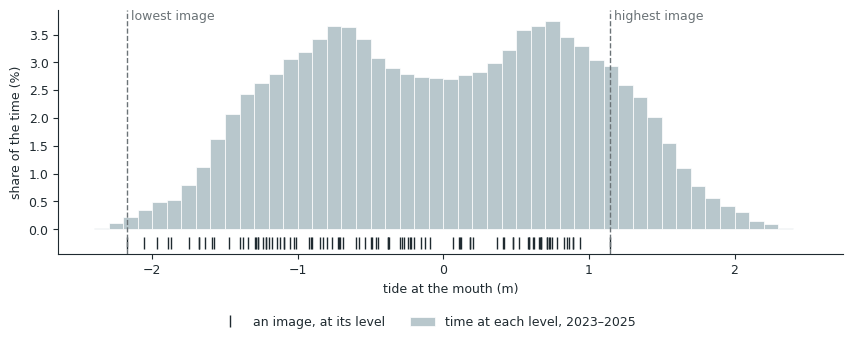

In [6]:
cov = coverage.tidal_range_coverage(h0, hs)                 # the images' span over the tide range of 2023-2025
gaps = coverage.gap_statistics(h0)                          # the gaps between consecutive levels, sorted
pct, lowest, highest = cov['coverage_pct'], cov['sampled_min'], cov['sampled_max']
low, high = cov['reference_min'], cov['reference_max']
gap_a, gap_b = gaps['max_gap_between']
mean_cm, max_cm = 100 * gaps['mean_gap'], 100 * gaps['max_gap']
above, under = 100 * (hs > highest).mean(), 100 * (hs < lowest).mean()
print(f'The {len(h0)} images between {t[0]:%d %b %Y} and {t[-1]:%d %b %Y}. They cover {pct:.0f} % of the tide range '
      f'(from {lowest:+.2f} to {highest:+.2f} m). Sorted by level, consecutive images are {mean_cm:.1f} cm apart on '
      f'average; the largest gap, {max_cm:.0f} cm, runs from {gap_a:+.2f} to {gap_b:+.2f} m.')
print(f'The tide of 2023–2025 runs from {low:+.2f} to {high:+.2f} m. It stands above the highest image '
      f'{above:.1f} % of the time and below the lowest {under:.1f} %.')

bins = np.arange(np.floor(low * 10) / 10, high + 0.1, 0.1)  # 10-cm classes of level
share, _ = np.histogram(hs, bins=bins)
fig, ax = plt.subplots(figsize=(8.6, 3.4))
ax.bar(bins[:-1], 100 * share / share.sum(), width=0.1, align='edge', color=RULE, edgecolor='white',
       linewidth=0.5, label='time at each level, 2023–2025')
ax.plot(h0, np.full(len(h0), -0.25), '|', color=INK, markersize=9, label='an image, at its level')
for v, name in ((lowest, 'lowest image'), (highest, 'highest image')):
    ax.axvline(v, color=GREY, lw=1, ls='--')
    ax.text(v, 1.0, f' {name}', transform=ax.get_xaxis_transform(), ha='left', va='top', color=GREY)
ax.set_xlabel('tide at the mouth (m)')
ax.set_ylabel('share of the time (%)')
fig.legend(loc='lower center', ncol=2)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()
s.close()

## On the website

The map viewer shows MAREA's maps of fourteen estuaries of northern Spain, ten of them preliminary: https://coastal-ai.github.io/Intertidal_analysis/. Heights there are given above NMMA, the mean sea level at Alicante; here they are on the scale of EOT20.

Data: contains modified Copernicus Sentinel data 2023–2025. Water levels: EOT20 (Hart-Davis et al. 2021, SEANOE, https://doi.org/10.17882/79489), CC BY 4.0.